In [ ]:
import nltk
from nltk.corpus import brown
from nltk.tokenize import word_tokenize

# Download required NLTK data
nltk.download('brown')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Load text from Brown Corpus (choose 'news' category)
text = " ".join(brown.words(categories='news'))

# Tokenize the text into words
tokens = word_tokenize(text)
print(f"Total tokens: {len(tokens)}")
print("First 20 tokens:", tokens[:20])


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Total tokens: 101929
First 20 tokens: ['The', 'Fulton', 'County', 'Grand', 'Jury', 'said', 'Friday', 'an', 'investigation', 'of', 'Atlanta', "'s", 'recent', 'primary', 'election', 'produced', '``', 'no', 'evidence', '``']


Top 20 words: [('the', 5580), (',', 5188), ('.', 4180), ('of', 2849), ('and', 2146), ('to', 2116), ('a', 1993), ('in', 1893), ('``', 1434), ('for', 943), ('that', 811), ('The', 806), ('is', 739), ('was', 720), ("'s", 679), ('on', 657), ('at', 598), ('with', 545), ('be', 526), ('by', 497)]


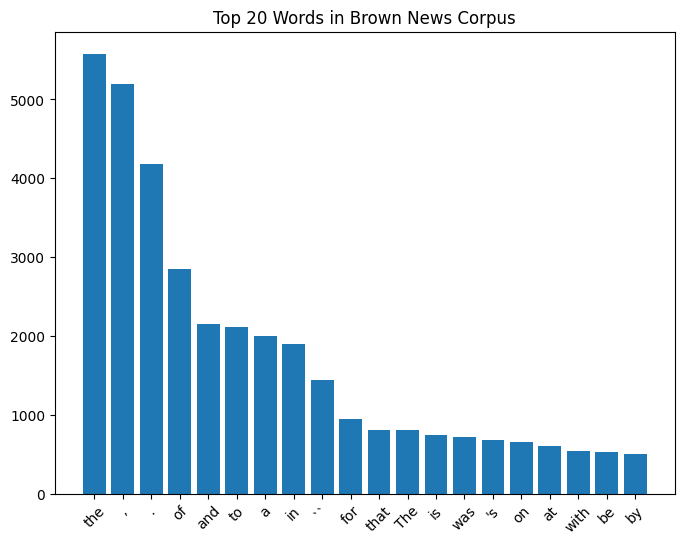

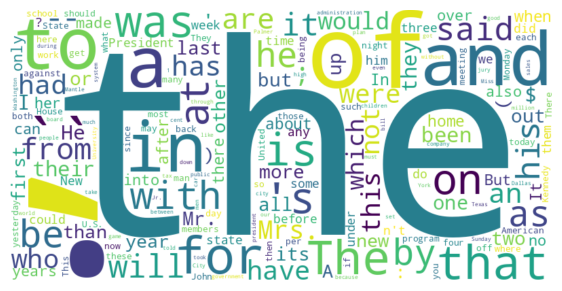

In [ ]:
from nltk import FreqDist
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Calculate frequency distribution
freq_dist = FreqDist(tokens)

# Top 20 words
top_words = freq_dist.most_common(20)
print("Top 20 words:", top_words)

# Bar chart
words, counts = zip(*top_words)
plt.figure(figsize=(8,6))
plt.bar(words, counts)
plt.xticks(rotation=45)
plt.title("Top 20 Words in Brown News Corpus")
plt.show()

# Word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(freq_dist)
plt.figure(figsize=(7,7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()


In [ ]:
from nltk.stem import PorterStemmer

ps = PorterStemmer()
stemmed_words = [ps.stem(word) for word in tokens]

# Frequency of stemmed words
stemmed_freq = FreqDist(stemmed_words)
top_stemmed = stemmed_freq.most_common(20)
print("Top 20 Stemmed Words:", top_stemmed)


Top 20 Stemmed Words: [('the', 6386), (',', 5188), ('.', 4180), ('of', 2861), ('and', 2186), ('to', 2144), ('a', 2139), ('in', 2020), ('``', 1434), ('for', 969), ('that', 843), ('is', 740), ('wa', 720), ('on', 691), ('it', 682), ("'s", 679), ('he', 658), ('at', 636), ('be', 583), ('with', 567)]


In [ ]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in tokens]

# Frequency of lemmatized words
lemmatized_freq = FreqDist(lemmatized_words)
top_lemmatized = lemmatized_freq.most_common(20)
print("Top 20 Lemmatized Words:", top_lemmatized)


Top 20 Lemmatized Words: [('the', 5580), (',', 5188), ('.', 4180), ('of', 2849), ('a', 2474), ('and', 2146), ('to', 2116), ('in', 1893), ('``', 1434), ('for', 943), ('that', 811), ('The', 806), ('is', 739), ('wa', 720), ("'s", 679), ('on', 657), ('at', 598), ('it', 549), ('with', 545), ('be', 526)]


          Word  Stemmed Count  Lemmatized Count
0      running             78                13
1          ran              9                 9
2         runs             78                65
3       easily              2                 2
4       fairly              3                 3
5         news             13                13
6   government             89                61
7    president            159                54
8       market             33                27
9        money             30                29
10       today             61                57
11   yesterday             57                57
12      people             58                54
13         man             78                75
14       woman              9                29


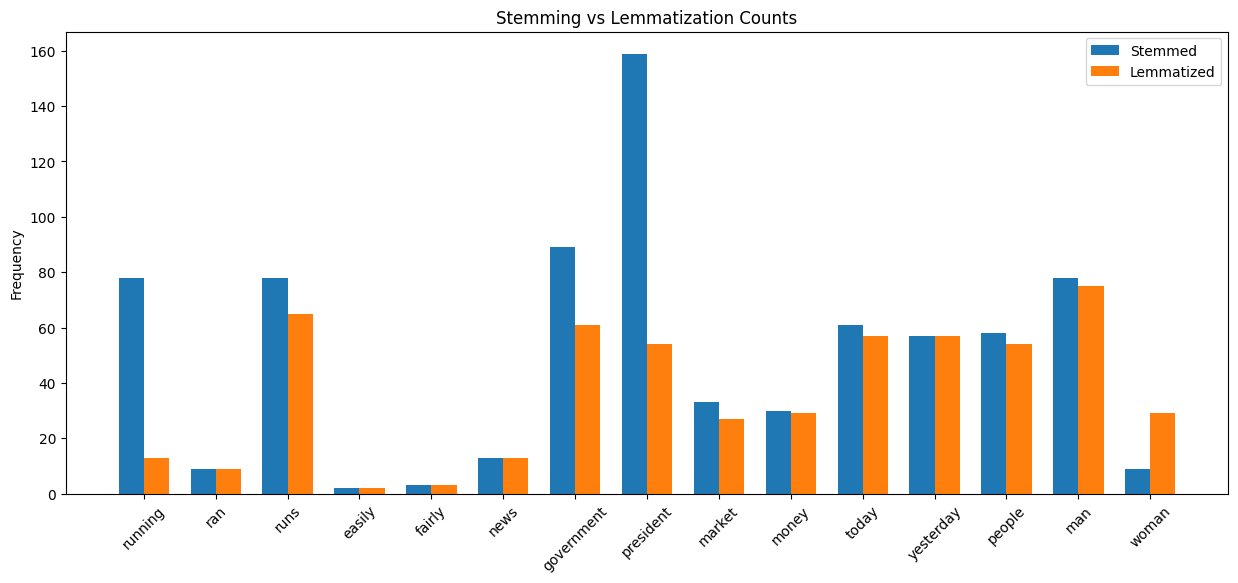

In [ ]:
import pandas as pd

# Select 15 common words to compare
common_words = ['running', 'ran', 'runs', 'easily', 'fairly', 'news', 'government', 'president', 'market', 'money', 'today', 'yesterday', 'people', 'man', 'woman']

data = []
for word in common_words:
    stem_count = stemmed_freq[ps.stem(word)]
    lemma_count = lemmatized_freq[lemmatizer.lemmatize(word)]
    data.append([word, stem_count, lemma_count])

df_compare = pd.DataFrame(data, columns=['Word', 'Stemmed Count', 'Lemmatized Count'])
print(df_compare)

# Optional: Side-by-side bar chart
import numpy as np

x = np.arange(len(common_words))
width = 0.35

plt.figure(figsize=(15,6))
plt.bar(x - width/2, df_compare['Stemmed Count'], width, label='Stemmed')
plt.bar(x + width/2, df_compare['Lemmatized Count'], width, label='Lemmatized')
plt.xticks(x, common_words, rotation=45)
plt.ylabel("Frequency")
plt.title("Stemming vs Lemmatization Counts")
plt.legend()
plt.show()